This notebook compares the performance of the embedding models by plotting the difference between their predicted similarities and the similarities from the annotated data.

Section 1 shows the performance of different albert models, for different distance metrics, then aggreagates models on all different metrics.

Section 2 shows the same for different bert models.

Section 3 shows the same for the remaining models.

Section 4 aggregates and sorts all models.

# 0. Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib import cm
import seaborn as sns; sns.set()

/usr/local/lib/python3.6/dist-packages/statsmodels/tools/_testing.py:19: FutureWarning: pandas.util.testing is deprecated. Use the functions in the public API at pandas.testing instead.
  import pandas.util.testing as tm


In [0]:
scores = pd.read_csv('berts_large_scores.csv')

In [0]:
sored_scores = scores.sort_values(by = 'score')

In [0]:
distance_metrics = ['cosine',
'minkowski',
'correlation',
'cityblock',
'sqeuclidean',
'euclidean',
'chebyshev',
'canberra',
'braycurtis']

In [0]:
alberts = scores[scores['method'].isin(['albert_xlarge', 'albert_base', 'albert_large', 'albert_xxlarge'])]
berts = scores[scores['method'].isin(['bert_wwm_u_L_24', 'bert_wwm_c_L_24', 'bert_c_L_12', 'bert_u_L_12', 'bert_c_L_24', 'bert_u_L_24' ])]
other = scores[scores['method'].isin(['use','elmo', 'nnlm', 'word2vec'])]
scores = scores[scores['method'].isin(['albert_xlarge', 'albert_base', 'albert_large', 'albert_xxlarge','bert_wwm_u_L_24', 'bert_wwm_c_L_24', 'bert_c_L_12', 'bert_u_L_12', 'bert_c_L_24', 'bert_u_L_24''use','elmo', 'nnlm', 'word2vec'])]

In [0]:
scores_subsets = [alberts, berts, other]

In [0]:
def plot_for_agg(grouped_scores):
  n_models = len(grouped_scores)
  data = [i for i in range(n_models)]
  my_cmap = cm.get_cmap('tab20')
  my_norm = Normalize(vmin=0, vmax=n_models)

  fig, ax = plt.subplots(figsize=(n_models*2,4))
  ax.bar(grouped_scores['score'].keys(), grouped_scores['score'], color=my_cmap(my_norm(data)))


  for index, value in enumerate(list(grouped_scores['score'])):
    plt.text(index-0.1, value, str(round(value,2)))
    
  ax.legend()
  plt.ylim((0,4.5))
  plt.show()


def plot_for_subset(scores_subset, model_names):
  my_cmap = cm.get_cmap('Accent')
  n_models = len(set(scores_subset['method']))
  my_norm = Normalize(vmin=0, vmax=n_models)
  data = [i for i in range(n_models)]

  for distance_metric in distance_metrics:
    fig, ax = plt.subplots(figsize=(n_models *2,4))
    grp =  scores_subset[scores_subset.metric == distance_metric]
    ax.bar(grp['method'], grp['score'], color=my_cmap(my_norm(data)))
    plt.title('{} models measured with {}'.format(model_names, distance_metric))
    plt.ylabel('Distance From Truth')
    plt.ylim((0,4.5))

    for index, value in enumerate(list(grp['score'])):
      plt.text(index-0.1, value, str(round(value,2)))

    plt.show()

# 1. Visualizing Alberts Performance

## 1.1. Best Model in The Alberts Group:

In [8]:
alberts[alberts['score'] == alberts['score'].min()]

,method,metric,score
120,albert_base,cityblock,2.262015


## 1.2. Visualizing Models in The Alberts Group:

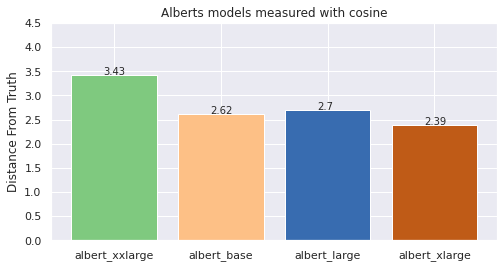

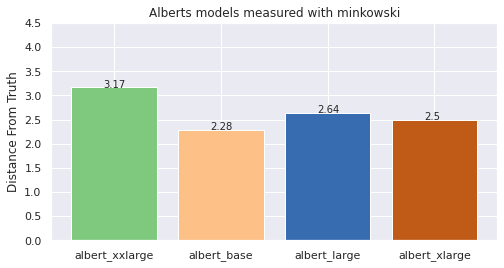

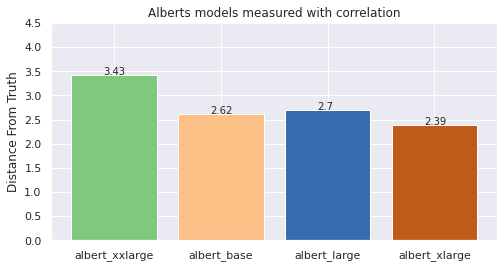

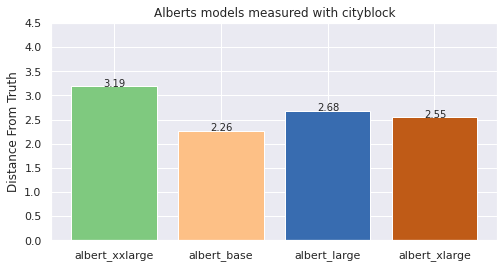

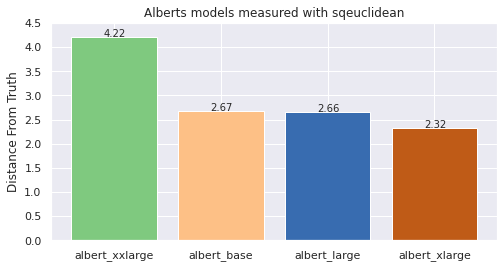

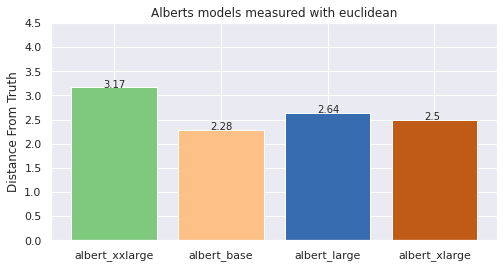

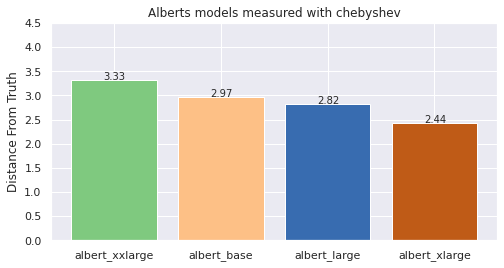

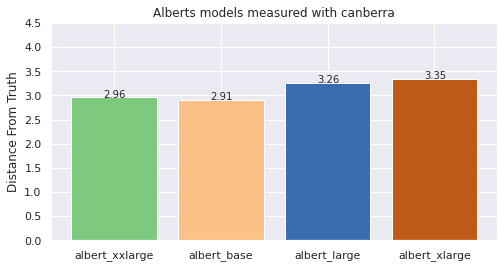

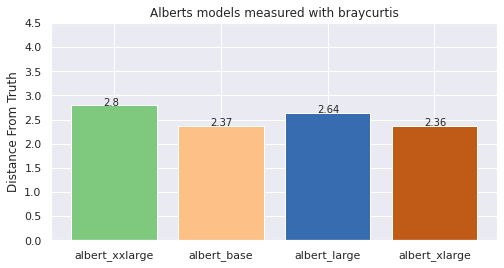

In [9]:
plot_for_subset(alberts, 'Alberts')

## 1.3. Aggregating Scores Per Model:

In [0]:
alberts_agg = alberts.groupby(by='method').mean()

### 1.3.1. Best Aggregated Model From The Alberts Group:

In [11]:
alberts_agg[alberts_agg['score'] == alberts_agg['score'].min()]

,score
method,
albert_xlarge,2.533424


### 1.3.2. Viusalizing Aggregated Models of The Alberts Group

No handles with labels found to put in legend.


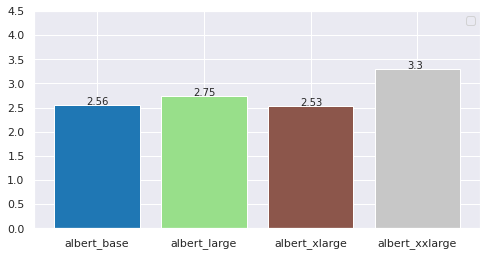

In [12]:
plot_for_agg(alberts_agg)

## 2.4. Conclusion About AlBerts

Best Model is 'albert base' when measured with 'cityblock', while the best aggregated model is 'albert xlarge' but both seem to have very close scores. So we check the variance of of the models, we can see that albert base has lower variance.

In [13]:
alberts.groupby(by='method').var()

,score
method,
albert_base,0.074411
albert_large,0.039529
albert_xlarge,0.098139
albert_xxlarge,0.162053


# 2. Visualizing Berts Performance

## 2.1. Best Model in The Berts Group:

In [14]:
berts[berts['score'] == berts['score'].min()]

,method,metric,score
92,bert_c_L_12,correlation,2.063929


## 2.2. Visualizing Models in The Berts Group:

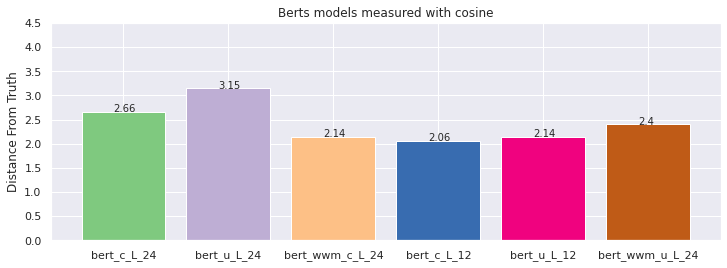

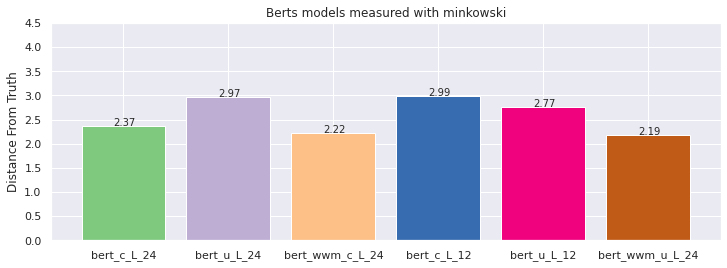

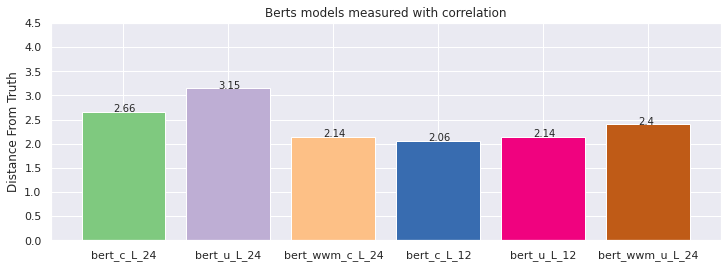

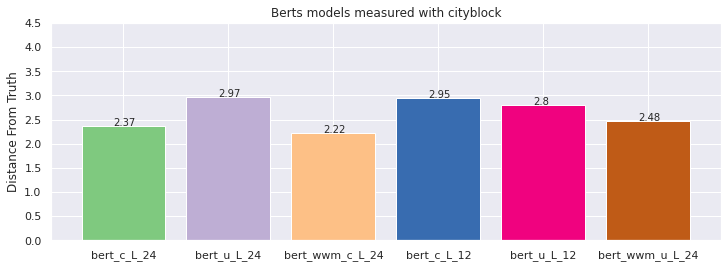

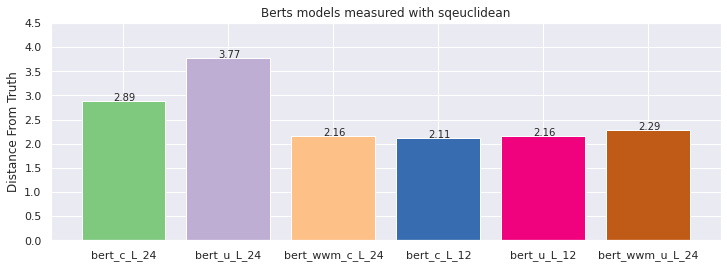

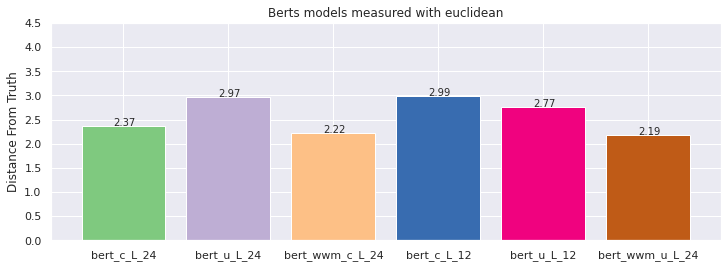

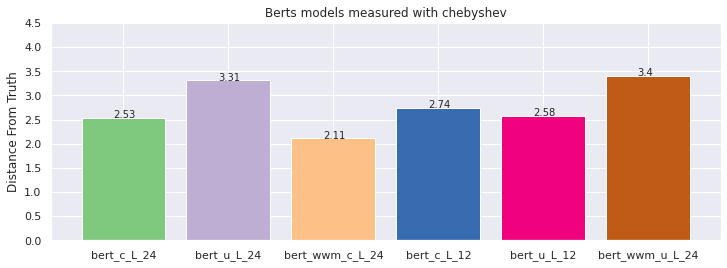

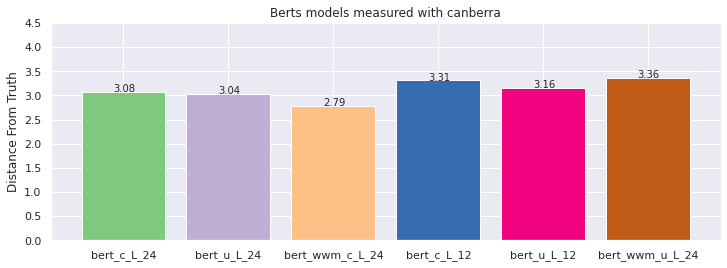

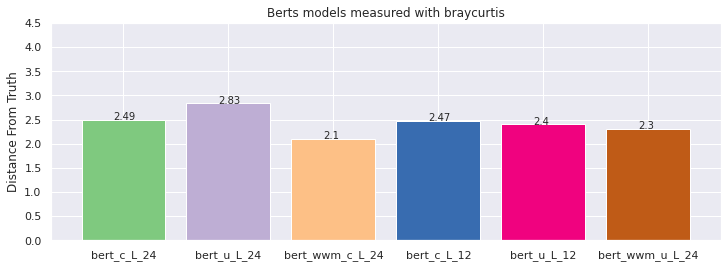

In [15]:
plot_for_subset(berts, 'Berts')

## 2.3. Aggregating Scores Per Model:

In [0]:
berts_agg = berts.groupby(by='method').mean()

### 2.3.1. Best Aggregated Model From The Berts Group:

In [17]:
berts_agg[berts_agg['score'] == berts_agg['score'].min()]

,score
method,
bert_wwm_c_L_24,2.23487


### 2.3.2. Viusalizing Aggregated Models of The Berts Group

No handles with labels found to put in legend.


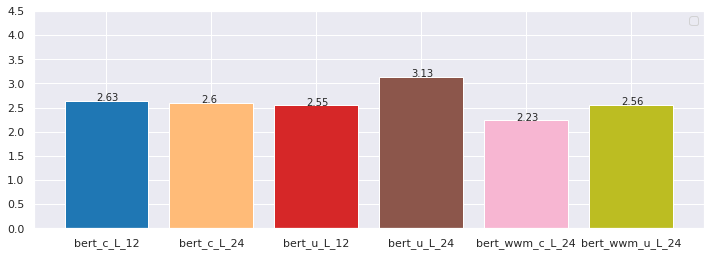

In [18]:
plot_for_agg(berts_agg)

## 2.4. Conclusion About Berts

Best Model is 'bert_wwm_c_L_24' when measured with 'correlation', and it is also the same when aggregating all distance metrics

# 3. Visualizing Other Models Performance

### 3.1. Best Model in The Other Models Group:

In [19]:
other[other['score'] == other['score'].min()]

,method,metric,score
47,use,correlation,1.61887


## 3.2. Visualizing Models in the Others Group:

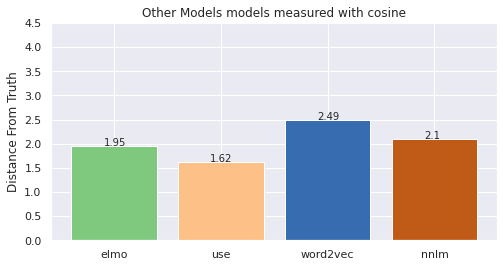

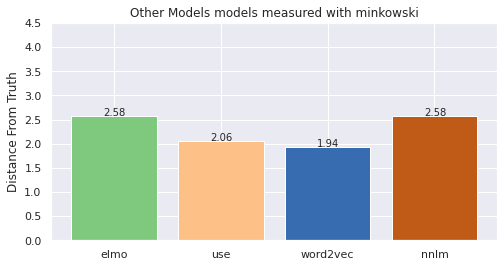

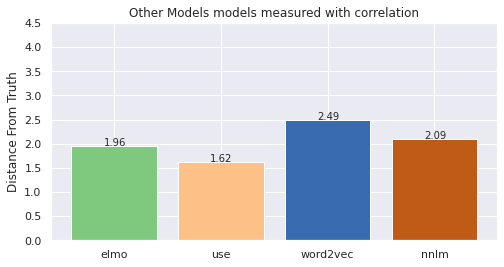

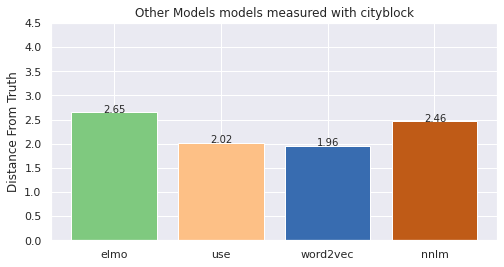

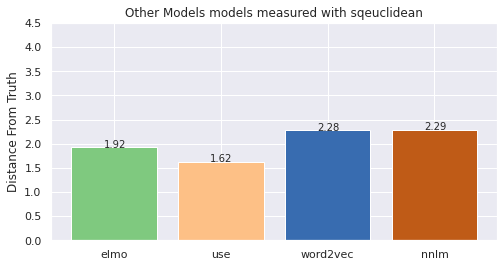

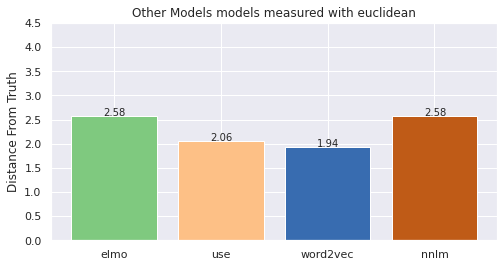

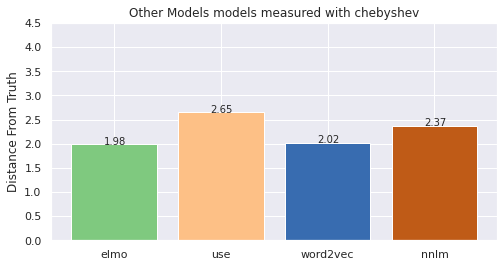

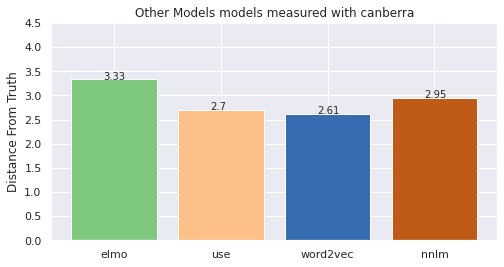

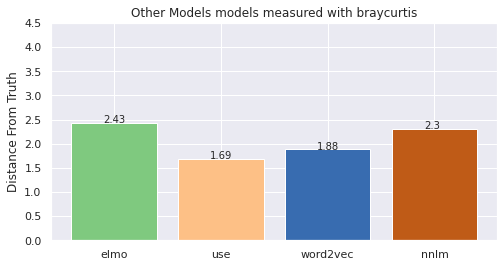

In [20]:
plot_for_subset(other, 'Other Models')

## 3.3. Aggregating Scores Per Model:

In [0]:
others_agg = other.groupby(by='method').mean()

### 3.3.1. Best Aggregated Model From The Others Group:

In [22]:
others_agg[others_agg['score'] == others_agg['score'].min()]

,score
method,
use,2.002611


### 3.3.2. Viusalizing Aggregated Models of The Othes Group

No handles with labels found to put in legend.


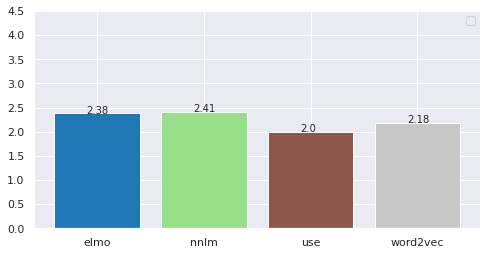

In [23]:
plot_for_agg(others_agg)

## 3.4. Conclusion About Berts

Best Model is 'use' when measured with 'correlation', and it is also the same when aggregating all distance metrics

## 4. All Models Sorted

In [0]:
sorted = scores.groupby("method").mean().sort_values(by = "score")

No handles with labels found to put in legend.


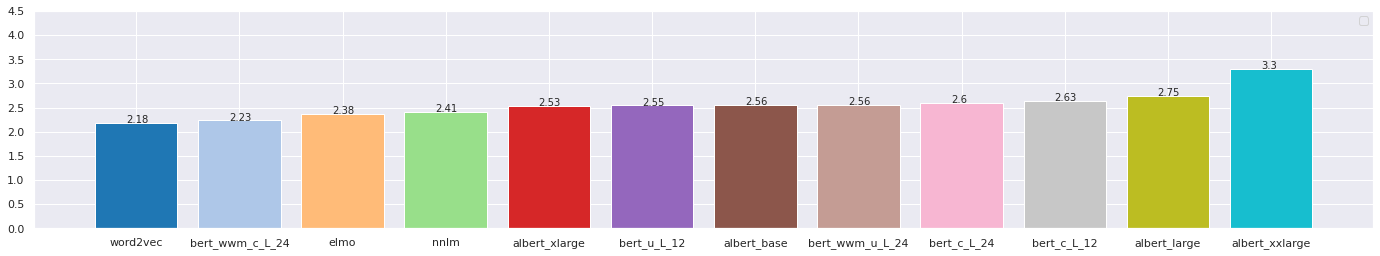

In [25]:
plot_for_agg(sorted)